In [4]:
import pandas as pd

df = pd.read_csv("online food delivery dataset.csv")
print(df.shape) 
df.head()

(388, 14)


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback,Unnamed: 13
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive,Yes


In [5]:
# Xóa cột thừa (trùng với Output)
df = df.drop(columns=["Unnamed: 13"])

# Cắt khoảng trắng thừa ở các cột chữ (vd "Negative ")
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Kiểm tra thiếu và trùng
print("Giá trị thiếu:", df.isna().sum().sum())   # kết quả đúng: 0
print("Dòng trùng:", df.duplicated().sum())      # kết quả đúng: 103

# Xóa dòng trùng
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)                                  # kết quả đúng: (285, 13)

Giá trị thiếu: 0
Dòng trùng: 103
(285, 13)


In [6]:
num_cols = ["Age", "Family size"]
cat_cols = ["Gender", "Marital Status", "Occupation",
            "Educational Qualifications", "Output", "Feedback"]

data = df[num_cols + cat_cols].copy()
print(data.shape)   # kết quả đúng: (285, 8)
data.head()

(285, 8)


,Age,Family size,Gender,Marital Status,Occupation,Educational Qualifications,Output,Feedback
0,20,4,Female,Single,Student,Post Graduate,Yes,Positive
1,24,3,Female,Single,Student,Graduate,Yes,Positive
2,22,3,Male,Single,Student,Post Graduate,Yes,Negative
3,22,6,Female,Single,Student,Graduate,Yes,Positive
4,22,4,Male,Single,Student,Post Graduate,Yes,Positive


In [7]:
from sklearn.preprocessing import StandardScaler

X = data.copy()
X[num_cols] = StandardScaler().fit_transform(X[num_cols])

# Chuyển sang mảng numpy và ghi lại vị trí các cột phân loại
X_arr = X.to_numpy()
cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))
print(cat_idx)      # kết quả đúng: [2, 3, 4, 5, 6, 7]
X.head()

[2, 3, 4, 5, 6, 7]


,Age,Family size,Gender,Marital Status,Occupation,Educational Qualifications,Output,Feedback
0,-1.540761,0.537115,Female,Single,Student,Post Graduate,Yes,Positive
1,-0.223081,-0.198836,Female,Single,Student,Graduate,Yes,Positive
2,-0.881921,-0.198836,Male,Single,Student,Post Graduate,Yes,Negative
3,-0.881921,2.009015,Female,Single,Student,Graduate,Yes,Positive
4,-0.881921,0.537115,Male,Single,Student,Post Graduate,Yes,Positive


In [8]:
import gower
import matplotlib.pyplot as plt
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score

# Ma trận khoảng cách Gower tính trên dữ liệu gốc (chưa chuẩn hóa)
data_g = data.copy()
data_g[cat_cols] = data_g[cat_cols].astype(object)
dist = gower.gower_matrix(data_g)

K_range = range(2, 11)
costs, sils = [], []

for k in K_range:
    kp = KPrototypes(n_clusters=k, init="Cao", n_init=5, random_state=42)
    labels = kp.fit_predict(X_arr, categorical=cat_idx)
    costs.append(kp.cost_)
    sils.append(silhouette_score(dist, labels, metric="precomputed"))
    print(f"K={k}: cost={kp.cost_:.1f}, silhouette={sils[-1]:.3f}")

K=2: cost=613.3, silhouette=0.320
K=3: cost=492.4, silhouette=0.081
K=4: cost=422.1, silhouette=0.086
K=5: cost=387.9, silhouette=0.084
K=6: cost=361.5, silhouette=0.087
K=7: cost=343.2, silhouette=0.084
K=8: cost=321.4, silhouette=0.066
K=9: cost=299.4, silhouette=0.087
K=10: cost=287.1, silhouette=0.028


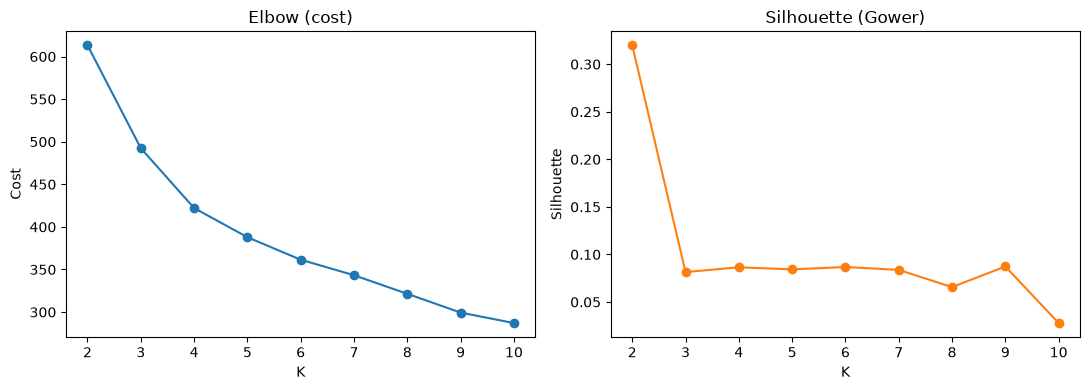

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(list(K_range), costs, marker="o")
ax[0].set_title("Elbow (cost)")
ax[0].set_xlabel("K")
ax[0].set_ylabel("Cost")

ax[1].plot(list(K_range), sils, marker="o", color="tab:orange")
ax[1].set_title("Silhouette (Gower)")
ax[1].set_xlabel("K")
ax[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

## Chọn số cụm K

Theo đề tài, K được chọn bằng phương pháp Elbow; Silhouette dùng để đối chiếu. Bảng dưới lấy từ vòng lặp ở trên.

In [10]:
from IPython.display import Markdown, display

k_table = pd.DataFrame({"K": list(K_range), "Cost": costs, "Silhouette": sils})
k_table["Cost giảm so với K-1 (%)"] = (-k_table["Cost"].pct_change() * 100)
display(k_table.round(3))

,K,Cost,Silhouette,Cost giảm so với K-1 (%)
0,2,613.311,0.320,NaN
1,3,492.404,0.081,19.714
2,4,422.126,0.086,14.272
3,5,387.892,0.084,8.110
4,6,361.481,0.087,6.809
5,7,343.242,0.084,5.046
6,8,321.441,0.066,6.352
7,9,299.392,0.087,6.860
8,10,287.104,0.028,4.104


**Chọn K = 4.**

- **Elbow:** cost giảm mạnh đến K = 4 (19,7% rồi 14,3%), từ K = 5 chỉ còn giảm khoảng 8% trở xuống, nên điểm khuỷu nằm ở K = 4.
- **Silhouette:** cao nhất ở K = 2 (0,320), nhưng 2 nhóm là quá thô để xây dựng chiến lược tiếp thị riêng. Từ K = 3 đến K = 9 giá trị gần như ngang nhau (khoảng 0,07 đến 0,09), nên K = 4 không kém các K lân cận.
- **Lưu ý:** Silhouette ở K = 4 chỉ khoảng 0,086, tức là các cụm chồng lấn nhiều, ranh giới giữa các cụm không rõ.

## Chạy K-Prototypes và gán nhãn cụm

Dùng cùng tham số với vòng lặp chọn K (`init="Cao"`, `n_init=5`, `random_state=42`). Số thứ tự cụm do thuật toán sinh ra là tùy ý, nên tên cụm được gán theo quy tắc dựa trên Family size và Age thay vì ghi cứng số cụm.

In [11]:
K = 4
if K != 4:
    raise ValueError("Tên cụm và chiến lược bên dưới được viết cho K = 4. Đổi K thì phải viết lại các phần đó.")

kp_final = KPrototypes(n_clusters=K, init="Cao", n_init=5, random_state=42)
labels = kp_final.fit_predict(X_arr, categorical=cat_idx)
print(f"cost = {kp_final.cost_:.1f}, gamma = {kp_final.gamma:.3f}, số vòng lặp = {kp_final.n_iter_}")

# Đặt tên cụm: 2 cụm Family size nhỏ / 2 cụm lớn, trong mỗi nhóm so sánh tuổi trung bình
means = data.groupby(labels)[num_cols].mean().sort_values("Family size")
small_family = means.iloc[:2].sort_values("Age").index
large_family = means.iloc[2:].sort_values("Age").index

segment_names = {
    small_family[0]: "Sinh viên hộ nhỏ",
    large_family[0]: "Sinh viên hộ đông",
    small_family[1]: "Người đi làm trẻ",
    large_family[1]: "Người có gia đình hộ đông",
}
segment_order = ["Sinh viên hộ nhỏ", "Sinh viên hộ đông",
                 "Người đi làm trẻ", "Người có gia đình hộ đông"]

df_seg = df.copy()
df_seg["Cluster"] = labels
df_seg["Segment"] = pd.Categorical(df_seg["Cluster"].map(segment_names),
                                   categories=segment_order, ordered=True)

df_seg.to_csv("customer_segments.csv", index=False, encoding="utf-8-sig")
print("Đã lưu nhãn cụm vào customer_segments.csv")
df_seg[["Age", "Family size", "Occupation", "Marital Status", "Cluster", "Segment"]].head()

cost = 422.1, gamma = 0.500, số vòng lặp = 4
Đã lưu nhãn cụm vào customer_segments.csv


,Age,Family size,Occupation,Marital Status,Cluster,Segment
0,20,4,Student,Single,2,Sinh viên hộ đông
1,24,3,Student,Single,1,Sinh viên hộ nhỏ
2,22,3,Student,Single,1,Sinh viên hộ nhỏ
3,22,6,Student,Single,2,Sinh viên hộ đông
4,22,4,Student,Single,2,Sinh viên hộ đông


## Thống kê đặc điểm từng cụm

Biến số dùng giá trị gốc (chưa chuẩn hóa) để dễ đọc.

- `Monthly Income` không tham gia phân cụm, chỉ dùng để tham khảo khi mô tả cụm.
- `Customer Type` không được dùng: cột này suy ra hoàn toàn từ `Family size` (1 người là New, 2–3 là Regular, từ 4 trở lên là Frequent), nên không cho biết thêm thông tin nào về hành vi mua.

In [12]:
high_income = ["25001 to 50000", "More than 50000"]

g = df_seg.groupby("Segment", observed=True)
profile = pd.DataFrame({
    "Số khách": g.size(),
    "Tỷ lệ (%)": g.size() / len(df_seg) * 100,
    "Age TB": g["Age"].mean(),
    "Family size TB": g["Family size"].mean(),
    "Gender phổ biến": g["Gender"].agg(lambda s: s.mode()[0]),
    "Marital Status phổ biến": g["Marital Status"].agg(lambda s: s.mode()[0]),
    "Occupation phổ biến": g["Occupation"].agg(lambda s: s.mode()[0]),
    "Education phổ biến": g["Educational Qualifications"].agg(lambda s: s.mode()[0]),
    "Output = Yes (%)": g["Output"].agg(lambda s: (s == "Yes").mean() * 100),
    "Feedback = Positive (%)": g["Feedback"].agg(lambda s: (s == "Positive").mean() * 100),
    "Không có thu nhập (%)": g["Monthly Income"].agg(lambda s: (s == "No Income").mean() * 100),
    "Thu nhập > 25.000 (%)": g["Monthly Income"].agg(lambda s: s.isin(high_income).mean() * 100),
}).round(1)
display(profile.T)

# Tỷ lệ % từng giá trị của biến phân loại trong mỗi cụm
for col in cat_cols + ["Monthly Income"]:
    display(pd.crosstab(df_seg["Segment"], df_seg[col], normalize="index").mul(100).round(1))

Segment,Sinh viên hộ nhỏ,Sinh viên hộ đông,Người đi làm trẻ,Người có gia đình hộ đông
Số khách,113,64,65,43
Tỷ lệ (%),39.6,22.5,22.8,15.1
Age TB,22.8,22.9,26.5,29.5
Family size TB,2.4,4.6,2.4,4.9
Gender phổ biến,Male,Male,Male,Male
Marital Status phổ biến,Single,Single,Married,Married
Occupation phổ biến,Student,Student,Employee,Employee
Education phổ biến,Post Graduate,Post Graduate,Graduate,Graduate
Output = Yes (%),83.2,93.8,64.6,48.8
Feedback = Positive (%),84.1,93.8,75.4,62.8


Gender,Female,Male
Segment,,
Sinh viên hộ nhỏ,39.8,60.2
Sinh viên hộ đông,45.3,54.7
Người đi làm trẻ,41.5,58.5
Người có gia đình hộ đông,46.5,53.5


Marital Status,Married,Prefer not to say,Single
Segment,,,
Sinh viên hộ nhỏ,4.4,1.8,93.8
Sinh viên hộ đông,12.5,1.6,85.9
Người đi làm trẻ,55.4,6.2,38.5
Người có gia đình hộ đông,88.4,4.7,7.0


Occupation,Employee,House wife,Self Employeed,Student
Segment,,,,
Sinh viên hộ nhỏ,14.2,0.0,3.5,82.3
Sinh viên hộ đông,18.8,1.6,6.2,73.4
Người đi làm trẻ,66.2,0.0,29.2,4.6
Người có gia đình hộ đông,53.5,18.6,25.6,2.3


Educational Qualifications,Graduate,Ph.D,Post Graduate,School,Uneducated
Segment,,,,,
Sinh viên hộ nhỏ,39.8,3.5,54.9,1.8,0.0
Sinh viên hộ đông,37.5,6.2,54.7,1.6,0.0
Người đi làm trẻ,53.8,9.2,35.4,1.5,0.0
Người có gia đình hộ đông,51.2,16.3,11.6,16.3,4.7


Output,No,Yes
Segment,,
Sinh viên hộ nhỏ,16.8,83.2
Sinh viên hộ đông,6.2,93.8
Người đi làm trẻ,35.4,64.6
Người có gia đình hộ đông,51.2,48.8


Feedback,Negative,Positive
Segment,,
Sinh viên hộ nhỏ,15.9,84.1
Sinh viên hộ đông,6.2,93.8
Người đi làm trẻ,24.6,75.4
Người có gia đình hộ đông,37.2,62.8


Monthly Income,10001 to 25000,25001 to 50000,Below Rs.10000,More than 50000,No Income
Segment,,,,,
Sinh viên hộ nhỏ,10.6,8.0,8.0,4.4,69.0
Sinh viên hộ đông,15.6,3.1,6.2,9.4,65.6
Người đi làm trẻ,15.4,43.1,7.7,30.8,3.1
Người có gia đình hộ đông,9.3,30.2,2.3,37.2,20.9


## Biểu đồ phân bố khách hàng theo cụm

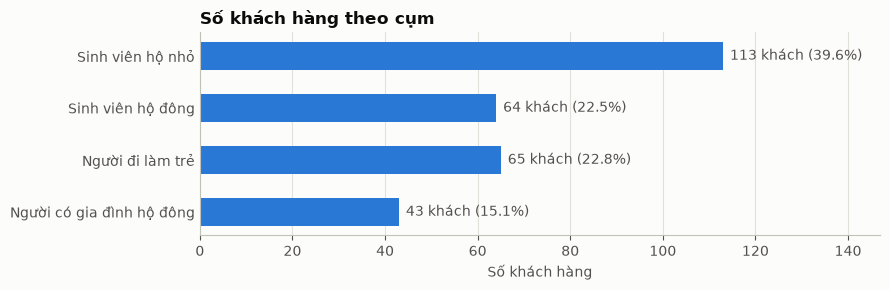

In [13]:
INK, INK_2, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

# Số khách hàng theo cụm
sizes = df_seg["Segment"].value_counts().reindex(segment_order)
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(segment_order, sizes, color=PALETTE[0], height=0.55)
for y, n in enumerate(sizes):
    ax.text(n + 1.5, y, f"{n} khách ({n / len(df_seg):.1%})", va="center", color=INK_2)
ax.invert_yaxis()
ax.set_xlim(0, sizes.max() * 1.3)
ax.set_xlabel("Số khách hàng")
ax.set_title("Số khách hàng theo cụm")
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

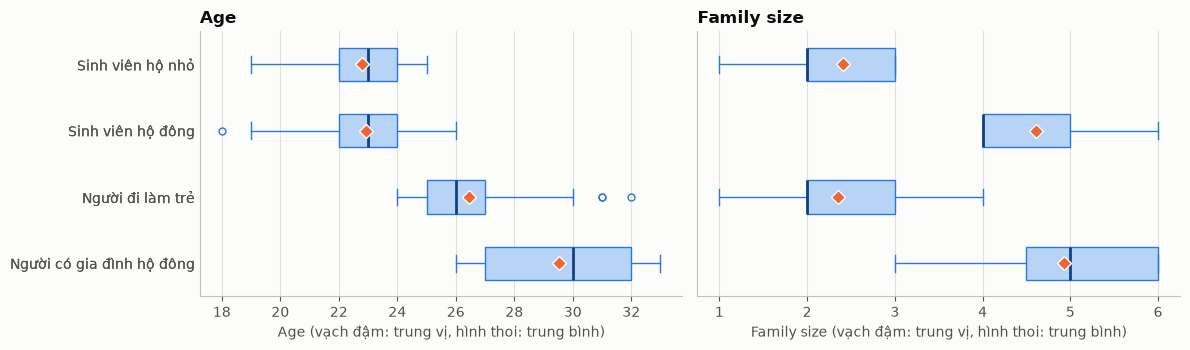

In [14]:
# Phân bố các biến số theo cụm
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, col in zip(axes, num_cols):
    values = [df_seg.loc[df_seg["Segment"] == s, col] for s in segment_order]
    ax.boxplot(values, orientation="horizontal", tick_labels=segment_order, widths=0.5,
               patch_artist=True, showmeans=True,
               boxprops={"facecolor": "#b7d3f6", "edgecolor": PALETTE[0]},
               medianprops={"color": "#104281", "linewidth": 2},
               whiskerprops={"color": PALETTE[0]}, capprops={"color": PALETTE[0]},
               flierprops={"markeredgecolor": PALETTE[0], "markersize": 5},
               meanprops={"marker": "D", "markerfacecolor": PALETTE[1],
                          "markeredgecolor": SURFACE, "markersize": 7})
    ax.set_title(col)
    ax.set_xlabel(f"{col} (vạch đậm: trung vị, hình thoi: trung bình)")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()
axes[0].tick_params(axis="y", length=0)
axes[1].tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

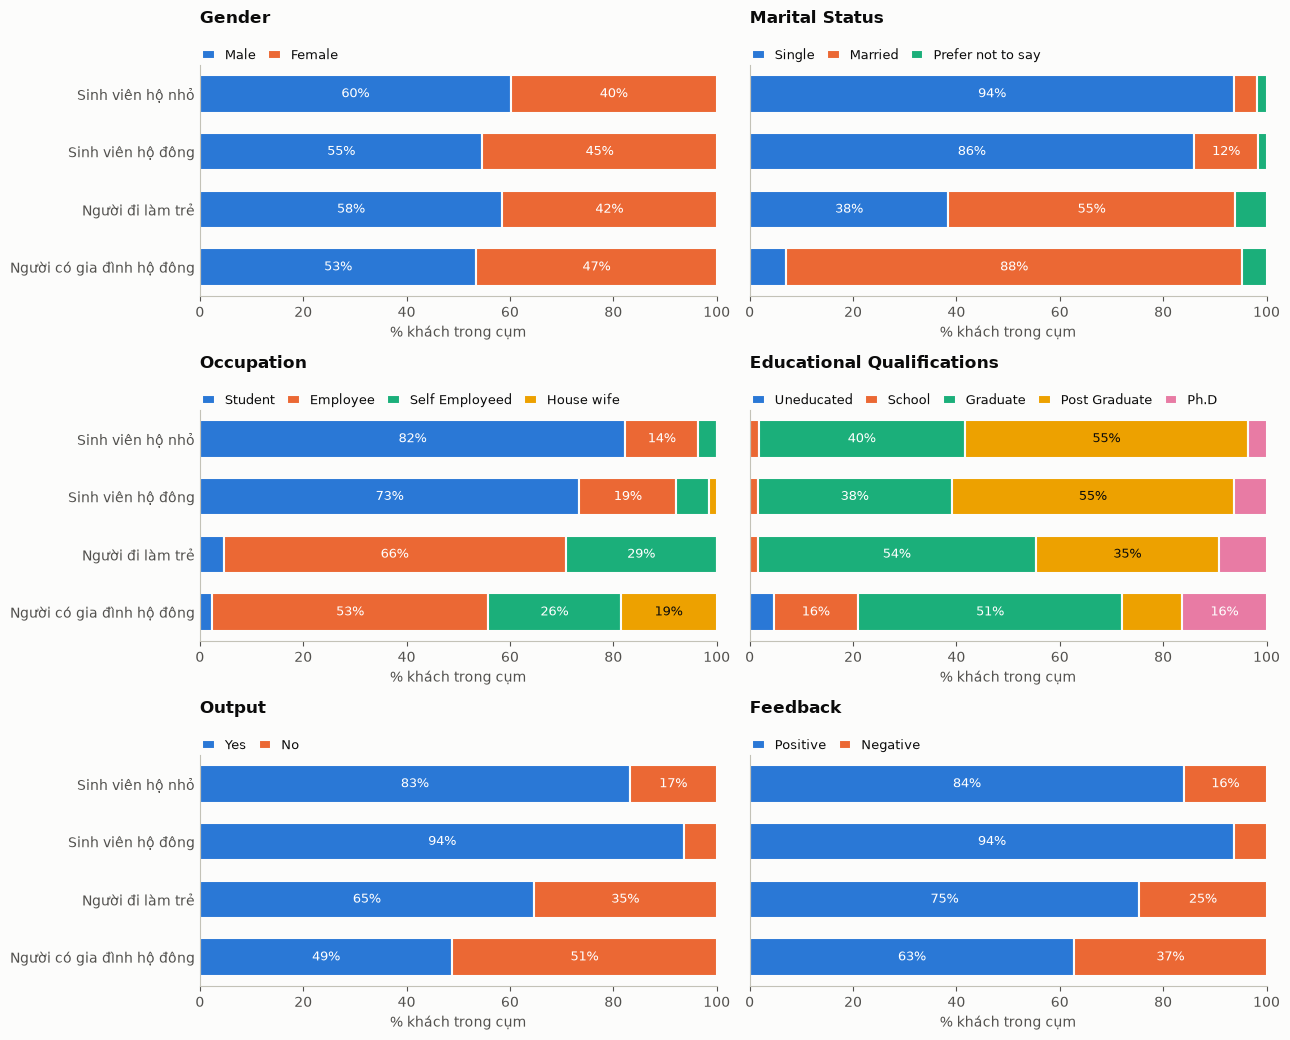

In [15]:
# Cơ cấu các biến phân loại trong từng cụm (% khách của cụm)
category_order = {
    "Gender": ["Male", "Female"],
    "Marital Status": ["Single", "Married", "Prefer not to say"],
    "Occupation": ["Student", "Employee", "Self Employeed", "House wife"],
    "Educational Qualifications": ["Uneducated", "School", "Graduate", "Post Graduate", "Ph.D"],
    "Output": ["Yes", "No"],
    "Feedback": ["Positive", "Negative"],
}

fig, axes = plt.subplots(3, 2, figsize=(13, 10.5), sharey=True)
for ax, col in zip(axes.ravel(), cat_cols):
    pct = (pd.crosstab(df_seg["Segment"], df_seg[col], normalize="index") * 100)
    pct = pct.reindex(index=segment_order, columns=category_order[col], fill_value=0)
    left = pd.Series(0.0, index=pct.index)
    for color, value in zip(PALETTE, pct.columns):
        ax.barh(segment_order, pct[value], left=left, height=0.65, color=color,
                edgecolor=SURFACE, linewidth=1.5, label=value)
        for y, s in enumerate(segment_order):
            if pct.loc[s, value] >= 12:
                ax.text(left[s] + pct.loc[s, value] / 2, y, f"{pct.loc[s, value]:.0f}%",
                        ha="center", va="center", fontsize=9,
                        color=INK if color == "#eda100" else "white")
        left = left + pct[value]
    ax.set_xlim(0, 100)
    ax.set_title(col, pad=30)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=5, frameon=False,
              fontsize=9, handlelength=1, columnspacing=1, borderaxespad=0, borderpad=0.2)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("% khách trong cụm")
axes[0, 0].invert_yaxis()
plt.tight_layout()
plt.show()

## Đặt tên cụm và đề xuất chiến lược tiếp thị

Bộ dữ liệu không có tài liệu chính thức về cột `Output`. Phần này **giả định `Output = Yes` nghĩa là khách tiếp tục đặt món online**; nếu nguồn dữ liệu định nghĩa khác thì cần xem lại chiến lược. Số liệu trong phần mô tả được lấy trực tiếp từ bảng `profile`.

In [16]:
strategies = {
    "Sinh viên hộ nhỏ": [
        "Nhóm đông nhất nhưng đa số chưa có thu nhập: ưu tiên mã giảm giá sinh viên và ưu đãi theo khung giờ.",
        "Thiết kế suất ăn một người giá thấp, miễn phí giao hàng cho đơn nhỏ.",
        "Tiếp cận qua mạng xã hội và hợp tác với trường đại học, câu lạc bộ sinh viên.",
    ],
    "Sinh viên hộ đông": [
        "Nhóm có Output và phản hồi tích cực cao nhất: tập trung giữ chân bằng chương trình điểm thưởng.",
        "Khuyến khích giới thiệu bạn bè, thưởng cho cả người giới thiệu và người được giới thiệu.",
        "Đẩy combo nhóm và combo gia đình để tăng giá trị mỗi đơn.",
    ],
    "Người đi làm trẻ": [
        "Đa số có thu nhập trên 25.000, phần lớn đang đi làm nên cần sự tiện lợi: tung gói giao bữa trưa văn phòng và gói đăng ký theo tháng.",
        "Cam kết thời gian giao đúng giờ, gợi ý thực đơn cao cấp hơn thay vì giảm giá sâu.",
        "Thu thập phản hồi sau đơn hàng để cải thiện tỷ lệ phản hồi tích cực còn ở mức trung bình.",
    ],
    "Người có gia đình hộ đông": [
        "Đa số có thu nhập trên 25.000 nhưng Output và phản hồi tích cực thấp nhất: ưu tiên khảo sát lý do không hài lòng trước khi chi cho quảng cáo.",
        "Cải thiện chất lượng dịch vụ, rồi gửi ưu đãi mời quay lại cho khách từng phản hồi tiêu cực.",
        "Giới thiệu combo gia đình và đặt lịch trước cho bữa tối, cuối tuần.",
    ],
}

parts = []
for s in segment_order:
    p = profile.loc[s]
    parts.append(
        f"### {s} ({p['Số khách']} khách, {p['Tỷ lệ (%)']}%)\n\n"
        f"**Đặc điểm:** tuổi TB {p['Age TB']}, quy mô hộ TB {p['Family size TB']}; "
        f"phổ biến nhất: {p['Occupation phổ biến']}, {p['Marital Status phổ biến']}, "
        f"{p['Education phổ biến']}. Output = Yes {p['Output = Yes (%)']}%, "
        f"Feedback tích cực {p['Feedback = Positive (%)']}%, "
        f"thu nhập trên 25.000 {p['Thu nhập > 25.000 (%)']}%, "
        f"không có thu nhập {p['Không có thu nhập (%)']}%.\n\n"
        "**Chiến lược:**\n\n" + "\n".join(f"- {t}" for t in strategies[s])
    )
display(Markdown("\n\n".join(parts)))

### Sinh viên hộ nhỏ (113 khách, 39.6%)

**Đặc điểm:** tuổi TB 22.8, quy mô hộ TB 2.4; phổ biến nhất: Student, Single, Post Graduate. Output = Yes 83.2%, Feedback tích cực 84.1%, thu nhập trên 25.000 12.4%, không có thu nhập 69.0%.

**Chiến lược:**

- Nhóm đông nhất nhưng đa số chưa có thu nhập: ưu tiên mã giảm giá sinh viên và ưu đãi theo khung giờ.
- Thiết kế suất ăn một người giá thấp, miễn phí giao hàng cho đơn nhỏ.
- Tiếp cận qua mạng xã hội và hợp tác với trường đại học, câu lạc bộ sinh viên.

### Sinh viên hộ đông (64 khách, 22.5%)

**Đặc điểm:** tuổi TB 22.9, quy mô hộ TB 4.6; phổ biến nhất: Student, Single, Post Graduate. Output = Yes 93.8%, Feedback tích cực 93.8%, thu nhập trên 25.000 12.5%, không có thu nhập 65.6%.

**Chiến lược:**

- Nhóm có Output và phản hồi tích cực cao nhất: tập trung giữ chân bằng chương trình điểm thưởng.
- Khuyến khích giới thiệu bạn bè, thưởng cho cả người giới thiệu và người được giới thiệu.
- Đẩy combo nhóm và combo gia đình để tăng giá trị mỗi đơn.

### Người đi làm trẻ (65 khách, 22.8%)

**Đặc điểm:** tuổi TB 26.5, quy mô hộ TB 2.4; phổ biến nhất: Employee, Married, Graduate. Output = Yes 64.6%, Feedback tích cực 75.4%, thu nhập trên 25.000 73.8%, không có thu nhập 3.1%.

**Chiến lược:**

- Đa số có thu nhập trên 25.000, phần lớn đang đi làm nên cần sự tiện lợi: tung gói giao bữa trưa văn phòng và gói đăng ký theo tháng.
- Cam kết thời gian giao đúng giờ, gợi ý thực đơn cao cấp hơn thay vì giảm giá sâu.
- Thu thập phản hồi sau đơn hàng để cải thiện tỷ lệ phản hồi tích cực còn ở mức trung bình.

### Người có gia đình hộ đông (43 khách, 15.1%)

**Đặc điểm:** tuổi TB 29.5, quy mô hộ TB 4.9; phổ biến nhất: Employee, Married, Graduate. Output = Yes 48.8%, Feedback tích cực 62.8%, thu nhập trên 25.000 67.4%, không có thu nhập 20.9%.

**Chiến lược:**

- Đa số có thu nhập trên 25.000 nhưng Output và phản hồi tích cực thấp nhất: ưu tiên khảo sát lý do không hài lòng trước khi chi cho quảng cáo.
- Cải thiện chất lượng dịch vụ, rồi gửi ưu đãi mời quay lại cho khách từng phản hồi tiêu cực.
- Giới thiệu combo gia đình và đặt lịch trước cho bữa tối, cuối tuần.